# EN4554 Assignment 2 — Convolutional Neural Networks

**Name:** _your name_
**Index number:** _your index_
**GitHub repository:** _link_

**AI tool acknowledgement:** Claude (Anthropic) was used as a coding and learning assistant for this assignment. All code was reviewed, run, and understood by me.

## Setup

* Dataset: CIFAR-10, 50k training images split into **45k train / 5k validation** (fixed random permutation).
* Normalisation: per-channel mean and std computed on the **45k training images only**, then applied to train and validation. Computing statistics on validation or test data would leak information about the data we evaluate on.
* Seeds: Python, NumPy and PyTorch seeds are fixed so the results are reproducible.
* The test set is **not loaded here**. It is used once, in Task 4.

The whole dataset is small (45k × 3 × 32 × 32 floats ≈ 550 MB), so it is kept on the GPU as one tensor and mini-batches are taken by indexing. This is much faster than a `DataLoader` for CIFAR-sized data.

In [1]:
import math, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 0
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

PyTorch 2.6.0+cu124 | device: cuda | NVIDIA GeForce RTX 3090


In [2]:
train_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
classes = train_full.classes

# uint8 (50000, 32, 32, 3)  ->  float (50000, 3, 32, 32) in [0, 1]
X_all = torch.tensor(train_full.data).permute(0, 3, 1, 2).float() / 255.0
Y_all = torch.tensor(train_full.targets)

# Fixed 45k / 5k split
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45000], perm[45000:]

# Per-channel statistics from the TRAINING split only
mean = X_all[train_idx].mean(dim=(0, 2, 3), keepdim=True)
std  = X_all[train_idx].std(dim=(0, 2, 3), keepdim=True)

X_train = ((X_all[train_idx] - mean) / std).to(device)
Y_train = Y_all[train_idx].to(device)
X_val   = ((X_all[val_idx] - mean) / std).to(device)
Y_val   = Y_all[val_idx].to(device)

print('train:', tuple(X_train.shape), ' val:', tuple(X_val.shape))
print('channel mean:', mean.flatten().numpy().round(4))
print('channel std :', std.flatten().numpy().round(4))
print('normalised train mean/std per channel:',
      X_train.mean(dim=(0, 2, 3)).cpu().numpy().round(3), X_train.std(dim=(0, 2, 3)).cpu().numpy().round(3))

train: (45000, 3, 32, 32)  val: (5000, 3, 32, 32)
channel mean: [0.4912 0.482  0.4464]
channel std : [0.2472 0.2436 0.2617]
normalised train mean/std per channel: [0. 0. 0.] [1. 1. 1.]


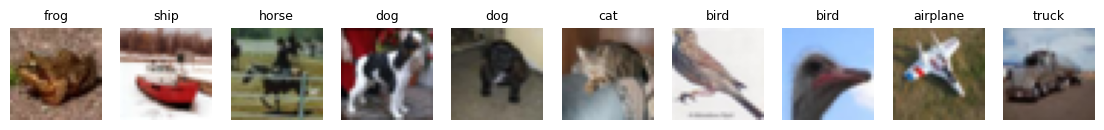

In [3]:
def batches(X, Y, batch_size, shuffle=True):
    # Yields mini-batches from tensors that already live on the GPU.
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), batch_size):
        j = idx[i:i + batch_size]
        yield X[j], Y[j]

# A few training images (un-normalised for display)
fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for ax, i in zip(axes, range(10)):
    img = (X_train[i].cpu() * std[0] + mean[0]).permute(1, 2, 0).clamp(0, 1)
    ax.imshow(img); ax.set_title(classes[Y_train[i]], fontsize=9); ax.axis('off')
plt.show()

---
## Task 1: Backpropagation

### 1(a) Layers with explicit forward/backward, and an MLP

Each layer stores what it needs during `forward` and uses it in `backward`. `backward` receives $\frac{\partial L}{\partial \text{output}}$ (the *upstream gradient*) and returns $\frac{\partial L}{\partial \text{input}}$, so the gradient can be passed from layer to layer by the chain rule.

**Linear**: $Y = XW + b$, with $X \in \mathbb{R}^{N\times d_\text{in}}$, $W \in \mathbb{R}^{d_\text{in}\times d_\text{out}}$, $b \in \mathbb{R}^{d_\text{out}}$. Given $G = \frac{\partial L}{\partial Y}$:

$$\frac{\partial L}{\partial W} = X^\top G, \qquad \frac{\partial L}{\partial b} = \sum_{n=1}^{N} G_{n,:}, \qquad \frac{\partial L}{\partial X} = G\,W^\top$$

A quick way to remember these is to check the shapes: $\frac{\partial L}{\partial W}$ must have the same shape as $W$, which is $(d_\text{in}\times d_\text{out})$, and the only product of $X$ and $G$ with that shape is $X^\top G$. The bias is added to every row of the batch, so its gradient is the sum over the batch.

**ReLU**: $y = \max(0, x)$, so $\frac{\partial L}{\partial x} = \frac{\partial L}{\partial y}\cdot \mathbb{1}[x > 0]$. The gradient passes through where the input was positive and is blocked everywhere else.

**Softmax cross-entropy**: with logits $z$, $p = \text{softmax}(z)$ and the mean loss $L = -\frac{1}{N}\sum_n \log p_{n, y_n}$:

$$\frac{\partial L}{\partial z} = \frac{1}{N}\left(p - \text{onehot}(y)\right)$$

Softmax and cross-entropy are combined into one layer because the joint gradient is this simple expression, and because computing $\log$-softmax as $z - \max z - \log\sum e^{z - \max z}$ avoids overflow in `exp`.

**Initialisation**: weights are drawn from $\mathcal{N}(0, 2/d_\text{in})$ (He/Kaiming initialisation). A ReLU zeros about half its inputs, and the factor 2 compensates for that, so the activation scale stays roughly constant from layer to layer.

In [4]:
class Linear:
    # y = x @ W + b    x: (N, d_in)   W: (d_in, d_out)   b: (d_out,)
    def __init__(self, d_in, d_out, std=None, dtype=torch.float32):
        std = math.sqrt(2.0 / d_in) if std is None else std   # He init by default
        self.W = torch.randn(d_in, d_out, device=device, dtype=dtype) * std
        self.b = torch.zeros(d_out, device=device, dtype=dtype)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x                       # cache the input for backward
        return x @ self.W + self.b

    def backward(self, dout):            # dout = dL/dy, shape (N, d_out)
        self.dW = self.x.T @ dout        # (d_in, N) @ (N, d_out) -> (d_in, d_out)
        self.db = dout.sum(dim=0)        # b is added to every row -> sum over the batch
        return dout @ self.W.T           # dL/dx, shape (N, d_in)

    def params(self): return [self.W, self.b]
    def grads(self):  return [self.dW, self.db]


class ReLU:
    def forward(self, x):
        self.mask = x > 0                # remember where the input was positive
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask          # gradient flows only where x > 0

    def params(self): return []
    def grads(self):  return []


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        shifted = logits - logits.max(dim=1, keepdim=True).values      # avoids exp overflow
        log_probs = shifted - shifted.exp().sum(dim=1, keepdim=True).log()
        self.probs = log_probs.exp()
        self.y = y
        return -log_probs[torch.arange(len(y)), y].mean()

    def backward(self):
        N = len(self.y)
        dlogits = self.probs.clone()
        dlogits[torch.arange(N), self.y] -= 1                          # p - onehot(y)
        return dlogits / N                                             # /N because the loss is a mean


class MLP:
    # sizes = [3072, 256, 10] gives Linear(3072,256) -> act -> Linear(256,10)
    def __init__(self, sizes, activation=ReLU, std=None, dtype=torch.float32):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], std=std, dtype=dtype))
            if i < len(sizes) - 2:                                     # no activation after the last layer
                self.layers.append(activation())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        dout = self.loss_fn.backward()
        for layer in reversed(self.layers):
            dout = layer.backward(dout)

    def params(self): return [p for layer in self.layers for p in layer.params()]
    def grads(self):  return [g for layer in self.layers for g in layer.grads()]

In [5]:
# Sanity check: one forward and backward pass on a small batch
set_seed()
mlp = MLP([3 * 32 * 32, 256, 128, 10])
xb, yb = X_train[:64].flatten(1), Y_train[:64]

loss = mlp.loss(xb, yb)
mlp.backward()
print(f'initial loss = {loss.item():.4f}   (ln 10 = {math.log(10):.4f})')
for i, (p, g) in enumerate(zip(mlp.params(), mlp.grads())):
    print(f'param {i}: shape {tuple(p.shape)!s:14}  grad shape {tuple(g.shape)!s:14}  grad norm {g.norm():.4f}')

initial loss = 2.9846   (ln 10 = 2.3026)
param 0: shape (3072, 256)     grad shape (3072, 256)     grad norm 8.1965
param 1: shape (256,)          grad shape (256,)          grad norm 0.1789
param 2: shape (256, 128)      grad shape (256, 128)      grad norm 2.6846
param 3: shape (128,)          grad shape (128,)          grad norm 0.1739
param 4: shape (128, 10)       grad shape (128, 10)       grad norm 2.0742
param 5: shape (10,)           grad shape (10,)           grad norm 0.1872


**Interpretation.** Every gradient has the same shape as its parameter, which is necessary for a gradient-descent update $\theta \leftarrow \theta - \eta\,\nabla_\theta L$. A network that knows nothing about the classes and gives each of the 10 classes probability $1/10$ would have loss $\ln 10 \approx 2.30$, so this is the reference value for an untrained model. Our initial loss is somewhat higher. With He initialisation the initial logits are not all zero; their standard deviation is of order 1, so the softmax is not perfectly uniform and the network is slightly confident at random. A loss far above $\ln 10$ (e.g. 10 or more) would mean the initial weights are much too large. The gradients themselves are verified in Task 1(b).

### 1(b) Gradient check: autograd and centred finite differences

We check our hand-written gradients in two independent ways.

1. **Autograd.** The same network is rebuilt with PyTorch operations on copies of the same weights, and `loss.backward()` computes the reference gradients.
2. **Centred finite differences.** This uses only the definition of the derivative and needs no backward pass at all:
$$\frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta_i + h) - L(\theta_i - h)}{2h}$$
Each estimate needs two forward passes, and $W_1$ alone has about 200k entries, so we check a random sample of 20 entries per parameter tensor.

**Relative error** (per parameter tensor) is used instead of absolute error because it does not depend on the size of the gradient:
$$\text{rel. err}(a, b) = \frac{\lVert a - b\rVert}{\lVert a\rVert + \lVert b\rVert}$$
A value around $10^{-7}$ or smaller means the gradients agree; $10^{-2}$ or larger means a bug.

The check is done in **float64**, for a reason explained in the plot below.

In [6]:
import copy
import pandas as pd

def rel_error(a, b):
    # ||a - b|| / (||a|| + ||b||); 0 when identical, scale-independent
    return ((a - b).norm() / (a.norm() + b.norm()).clamp_min(1e-12)).item()

def numerical_grad(net, x, y, p, i, h=1e-5, centred=True):
    # Finite-difference estimate of dL/dp for the i-th entry of parameter p
    flat = p.view(-1)                      # a view, so changing flat changes p
    old = flat[i].item()
    flat[i] = old + h; L_plus = net.loss(x, y).item()
    if centred:
        flat[i] = old - h; L_minus = net.loss(x, y).item()
        flat[i] = old
        return (L_plus - L_minus) / (2 * h)
    flat[i] = old
    return (L_plus - net.loss(x, y).item()) / h

set_seed()
gc_net = MLP([3 * 32 * 32, 64, 32, 10], dtype=torch.float64)
xg, yg = X_train[:16].flatten(1).double(), Y_train[:16]

# 1) our manual backward pass
loss_manual = gc_net.loss(xg, yg)
gc_net.backward()
manual = [g.clone() for g in gc_net.grads()]

# 2) autograd on copies of the same parameters
params_ag = [p.clone().requires_grad_() for p in gc_net.params()]
h = xg
for i in range(0, len(params_ag), 2):
    h = h @ params_ag[i] + params_ag[i + 1]
    if i < len(params_ag) - 2:
        h = torch.relu(h)
loss_ag = F.cross_entropy(h, yg)
loss_ag.backward()
autograd = [p.grad for p in params_ag]
print(f'loss (ours) = {loss_manual.item():.12f}   loss (F.cross_entropy) = {loss_ag.item():.12f}')

# 3) centred finite differences on 20 random entries per tensor
rows = []
names = ['W1', 'b1', 'W2', 'b2', 'W3', 'b3']
for name, p, g_man, g_ag in zip(names, gc_net.params(), manual, autograd):
    idx = torch.randperm(p.numel())[:20]
    g_fd = torch.tensor([numerical_grad(gc_net, xg, yg, p, i) for i in idx.tolist()], dtype=torch.float64)
    g_man_s = g_man.view(-1)[idx].cpu()
    rows.append({
        'param': name, 'shape': tuple(p.shape),
        'rel. err vs autograd': rel_error(g_man, g_ag),
        'allclose (autograd)': torch.allclose(g_man, g_ag),
        'rel. err vs finite diff.': rel_error(g_man_s, g_fd),
        'allclose (finite diff.)': torch.allclose(g_man_s, g_fd, rtol=1e-5, atol=1e-7),
    })
pd.DataFrame(rows).style.format({'rel. err vs autograd': '{:.2e}', 'rel. err vs finite diff.': '{:.2e}'})

loss (ours) = 2.991249413305   loss (F.cross_entropy) = 2.991249413305


,param,shape,rel. err vs autograd,allclose (autograd),rel. err vs finite diff.,allclose (finite diff.)
0,W1,"(3072, 64)",6.45e-17,True,1.93e-10,True
1,b1,"(64,)",6.80e-17,True,2.68e-10,True
2,W2,"(64, 32)",4.31e-17,True,1.88e-10,True
3,b2,"(32,)",2.92e-17,True,1.10e-10,True
4,W3,"(32, 10)",6.15e-17,True,7.59e-11,True
5,b3,"(10,)",9.54e-17,True,8.94e-11,True


**Why centred differences and float64?** A finite-difference estimate has two sources of error that pull in opposite directions as $h$ changes:

* **Truncation error** (from the Taylor series). One-sided $\frac{L(\theta+h)-L(\theta)}{h}$ has error $O(h)$. Centred $\frac{L(\theta+h)-L(\theta-h)}{2h}$ has error $O(h^2)$ because the $h^2$ terms of the two Taylor expansions cancel. Smaller $h$ is better.
* **Rounding error.** $L(\theta+h)$ and $L(\theta-h)$ are nearly equal numbers; subtracting them loses precision, and dividing by $h$ magnifies it. This error is about $\varepsilon_\text{machine}/h$, so larger $h$ is better. $\varepsilon \approx 10^{-16}$ for float64 and $\approx 10^{-7}$ for float32.

The plot below measures this on 20 entries of $W_2$, using our float64 backward pass as the reference.

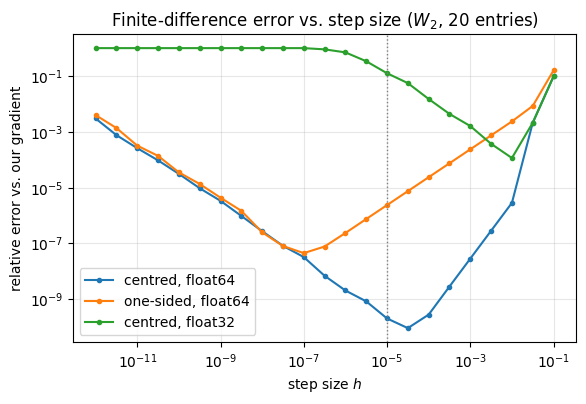

In [7]:
# Same weights in float32, for comparison
net32 = copy.deepcopy(gc_net)
for layer in net32.layers:
    if isinstance(layer, Linear):
        layer.W, layer.b = layer.W.float(), layer.b.float()

p64, p32 = gc_net.params()[2], net32.params()[2]          # W2 in both nets
idx = torch.randperm(p64.numel())[:20].tolist()
ref = manual[2].view(-1)[idx].cpu()
hs = np.logspace(-12, -1, 23)

curves = {'centred, float64': [], 'one-sided, float64': [], 'centred, float32': []}
for h in hs:
    fd_c64 = torch.tensor([numerical_grad(gc_net, xg, yg, p64, i, h) for i in idx], dtype=torch.float64)
    fd_o64 = torch.tensor([numerical_grad(gc_net, xg, yg, p64, i, h, centred=False) for i in idx], dtype=torch.float64)
    fd_c32 = torch.tensor([numerical_grad(net32, xg.float(), yg, p32, i, h) for i in idx], dtype=torch.float64)
    curves['centred, float64'].append(rel_error(ref, fd_c64))
    curves['one-sided, float64'].append(rel_error(ref, fd_o64))
    curves['centred, float32'].append(rel_error(ref, fd_c32))

plt.figure(figsize=(6.5, 4))
for label, errs in curves.items():
    plt.loglog(hs, errs, 'o-', ms=3, label=label)
plt.axvline(1e-5, color='gray', ls=':', lw=1)
plt.xlabel('step size $h$'); plt.ylabel('relative error vs. our gradient')
plt.title('Finite-difference error vs. step size ($W_2$, 20 entries)')
plt.legend(); plt.grid(True, which='both', alpha=0.3)
plt.show()

**Interpretation.**

* **Autograd:** the loss values agree to every printed digit, and the relative errors are about $10^{-16}$–$10^{-17}$, which is float64 machine precision. Our backward pass computes the same numbers as PyTorch's autograd up to rounding, and `torch.allclose` is `True` for all six tensors.
* **Finite differences:** the relative errors are about $10^{-10}$ and `allclose` is `True`. This error is not a flaw in our gradients; it is the error of the finite-difference estimate itself with $h = 10^{-5}$, as the plot shows. Agreement with a method that uses no derivatives at all confirms that the gradient formulas are mathematically correct, not just consistent with PyTorch.
* **The plot** has the expected V shape. To the right of the minimum, truncation error dominates: the centred curve rises with slope 2 ($O(h^2)$) and the one-sided curve with slope 1 ($O(h)$). To the left, rounding error ($\approx \varepsilon/h$) dominates and every curve rises as $h$ shrinks. The best step is roughly $\varepsilon^{1/3}$ for centred differences (about $10^{-5}$ in float64) and $\varepsilon^{1/2}$ for one-sided. That is why centred differences reach a lower error (about $10^{-11}$ versus $10^{-8}$).
* **float32** never gets better than about $10^{-4}$. For $h \lesssim 10^{-6}$ its relative error is exactly 1, because $\theta + h$ rounds back to $\theta$ in float32. Then $L(\theta+h) = L(\theta-h)$ and the estimate is 0. This is why gradient checks are done in float64.